# 02 — Análise de componentes principais (PCA) pela decomposição em valores singulares

Spec 002, perguntas Q2.1 e Q2.4. Este notebook mostra a PCA **passo a passo pela SVD** nos 3 sintomas de insônia
do NHANES 2005-06 (EUA) e do Vigitel 2024 (Brasil) e confere cada número com uma implementação de referência
(`scikit-learn`). No fim, resume os 10 conjuntos de itens da spec.

**Por que PCA aqui?** Queremos saber se os três sintomas (dificuldade para adormecer, para voltar a dormir e
acordar cedo demais) podem ser resumidos num único índice de insônia — o índice 0–12 usado nas specs 003 a 005.
A PCA procura as direções que concentram a maior parte da variância dos itens padronizados.

In [1]:
import sys, pathlib
raiz = pathlib.Path.cwd()
while not (raiz / "analise").is_dir():
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from analise.comum import caminhos, multivariada as mv
from analise.comum.estatistica import le_csv
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
TAB = caminhos.RESULTADOS / "002" / "tabelas"; FIG = caminhos.RESULTADOS / "002" / "figuras"

## Passo 1 — Padronizar

Cada item vira escore z: $Z_{ij} = (X_{ij} - \bar X_j) / s_j$, com desvio padrão amostral ($n-1$).
Assim a PCA trabalha sobre a **matriz de correlação**, e itens com escalas diferentes pesam igual.

In [2]:
nh = pd.read_parquet(caminhos.processado("nhanes0506"))
itens = ["sintoma_1", "sintoma_2", "sintoma_3"]
rotulos = ["adormecer", "voltar a dormir", "acordar cedo"]
X = nh[itens].dropna().to_numpy(float)
n, p = X.shape
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
print(f"n = {n} pessoas com os 3 itens; p = {p} itens")
print("médias de Z:", Z.mean(axis=0).round(12), "  DP de Z:", Z.std(axis=0, ddof=1).round(12))

n = 5551 pessoas com os 3 itens; p = 3 itens
médias de Z: [-0.  0.  0.]   DP de Z: [1. 1. 1.]


## Passo 2 — Decomposição em valores singulares

$$Z = U\,\Sigma\,V^\top$$

- $U$ ($n \times p$): direções no espaço das pessoas (colunas ortonormais);
- $\Sigma$: valores singulares $\sigma_1 \ge \sigma_2 \ge \sigma_3$;
- $V$ ($p \times p$): direções no espaço dos itens — os **vetores dos componentes**.

In [3]:
U, s, Vt = np.linalg.svd(Z, full_matrices=False)
V = Vt.T
V = V * np.sign(V.sum(axis=0))      # sinal é arbitrário; fixamos cargas positivas
print("U:", U.shape, " Σ:", s.round(3), " V:\n", pd.DataFrame(V, index=rotulos, columns=["CP1", "CP2", "CP3"]).round(3))
print("UᵀU = I ?", np.allclose(U.T @ U, np.eye(p)), "   VᵀV = I ?", np.allclose(V.T @ V, np.eye(p)))
print("Z = UΣVᵀ ?", np.allclose(Z, U @ np.diag(s) @ Vt))

U: (5551, 3)  Σ: [108.481  55.569  42.355]  V:
                    CP1    CP2    CP3
adormecer        0.544  0.787  0.291
voltar a dormir  0.612 -0.135 -0.780
acordar cedo     0.574 -0.602  0.555
UᵀU = I ? True    VᵀV = I ? True
Z = UΣVᵀ ? True


## Passo 3 — Autovalores e variância explicada

Como $Z^\top Z/(n-1) = R$ (a correlação), $R = V\,\frac{\Sigma^2}{n-1}\,V^\top$. Logo os **autovalores** da
correlação são $\lambda_k = \sigma_k^2/(n-1)$, e a proporção de variância do componente $k$ é $\lambda_k / p$.
Conferimos com os autovalores de $R$ e com o `PCA` do scikit-learn (tolerância $10^{-8}$).

In [4]:
lam = s**2 / (n - 1)
R = np.corrcoef(X, rowvar=False)
lam_R = np.sort(np.linalg.eigvalsh(R))[::-1]
from sklearn.decomposition import PCA
lam_sk = PCA().fit(Z).explained_variance_
print("λ pela SVD     :", lam.round(6))
print("λ de R (eigh)  :", lam_R.round(6))
print("λ scikit-learn :", lam_sk.round(6))
assert np.allclose(lam, lam_R, atol=1e-8) and np.allclose(lam, lam_sk, atol=1e-8)
print("diferença máxima SVD × scikit-learn:", np.abs(lam - lam_sk).max())
pd.DataFrame({"autovalor": lam, "% variância": 100 * lam / p, "% acumulada": 100 * np.cumsum(lam) / p},
             index=["CP1", "CP2", "CP3"]).round(2)

λ pela SVD     : [2.120389 0.556384 0.323227]
λ de R (eigh)  : [2.120389 0.556384 0.323227]
λ scikit-learn : [2.120389 0.556384 0.323227]
diferença máxima SVD × scikit-learn: 6.217248937900877e-15


,autovalor,% variância,% acumulada
CP1,2.12,70.68,70.68
CP2,0.56,18.55,89.23
CP3,0.32,10.77,100.00


## Passo 4 — Cargas e escores

- **Cargas**: $A = V\,\Sigma/\sqrt{n-1}$. Com dados padronizados, a carga do item $j$ no componente $k$ é a
  **correlação** entre o item e o escore do componente.
- **Escores**: $F = U\,\Sigma = Z\,V$ (uma linha por pessoa).

In [5]:
A = V * s / np.sqrt(n - 1)
F = Z @ V
print("F = UΣ ?", np.allclose(np.abs(F), np.abs(U * s)))
corr_item_cp1 = [np.corrcoef(Z[:, j], F[:, 0])[0, 1] for j in range(p)]
pd.DataFrame({"carga CP1": A[:, 0], "corr(item, escore CP1)": corr_item_cp1, "carga CP2": A[:, 1]}, index=rotulos).round(4)

F = UΣ ? True


,carga CP1,"corr(item, escore CP1)",carga CP2
adormecer,0.793,0.793,0.587
voltar a dormir,0.891,0.891,-0.101
acordar cedo,0.836,0.836,-0.449


**Leitura.** No NHANES o 1º componente tem autovalor 2,120 e explica
70,7% da variância dos três sintomas; os outros dois ficam abaixo de 1.
Todas as cargas do CP1 são altas e do mesmo sinal: o componente é um eixo de "insônia em geral".

## Passo 5 — Quantos componentes? Kaiser, scree e análise paralela

- **Kaiser**: reter $\lambda > 1$ (o componente explica mais que um item sozinho).
- **Scree**: procurar o "cotovelo" no gráfico dos autovalores.
- **Análise paralela de Horn (1965)**: gerar 1.000 conjuntos de dados aleatórios com o mesmo $n$ e $p$, sem
  nenhuma estrutura, e reter só os componentes cujo autovalor supera o **percentil 95** dos aleatórios.
  É a regra que decide no plano da spec 002.

In [6]:
pa = mv.analise_paralela(n, p, reps=1000, semente=2027)
pd.DataFrame({"observado": lam, "aleatório (média)": pa["media"], "aleatório (P95)": pa["p95"],
              "retém?": lam > pa["p95"]}, index=["CP1", "CP2", "CP3"]).round(4)

,observado,aleatório (média),aleatório (P95),retém?
CP1,2.120,1.021,1.038,True
CP2,0.556,1.000,1.008,False
CP3,0.323,0.979,0.992,False


## Brasil: o mesmo procedimento no Vigitel 2024

Usamos a função `mv.pca_svd` (o mesmo código acima, empacotado e testado em `tests/test_002_multivariada.py`).

In [7]:
vg = pd.read_parquet(caminhos.processado("vigitel2024"))
Xb = vg[itens].dropna().to_numpy(float)
rb, ru = mv.pca_svd(Xb), mv.pca_svd(X)
comp = pd.DataFrame({"carga CP1 Vigitel (BR)": rb["cargas"][:, 0], "carga CP1 NHANES (EUA)": ru["cargas"][:, 0]}, index=rotulos)
print(f"Vigitel: n = {len(Xb)}, λ1 = {rb['autovalores'][0]:.3f} ({100*rb['variancia'][0]:.1f}%)")
print(f"NHANES : n = {len(X)}, λ1 = {ru['autovalores'][0]:.3f} ({100*ru['variancia'][0]:.1f}%)")
print("Tucker φ entre as cargas do CP1:", round(mv.tucker(rb["cargas"][:, 0], ru["cargas"][:, 0]), 4))
comp.round(3)

Vigitel: n = 27048, λ1 = 2.261 (75.4%)
NHANES : n = 5551, λ1 = 2.120 (70.7%)
Tucker φ entre as cargas do CP1: 0.9998


,carga CP1 Vigitel (BR),carga CP1 NHANES (EUA)
adormecer,0.834,0.793
voltar a dormir,0.899,0.891
acordar cedo,0.871,0.836


**Leitura.** Nos dois países um único componente concentra a variância (Vigitel 75,4%,
NHANES 70,7%), e as cargas praticamente coincidem (Tucker φ = 1,000).
Isso sustenta usar a soma dos três sintomas como índice nas specs 003–005: a correlação entre a soma e o escore do CP1 é
≥ 0,999 nas duas bases (`resultados/002/tabelas/escores_correlacao.csv`).

## Os 10 conjuntos de itens da spec 002

In [8]:
ad = le_csv(TAB / "adequacao.csv")
ad[["conjunto", "n", "p", "lambda1", "var_pc1", "k_kaiser", "k_paralela"]]

,conjunto,n,p,lambda1,var_pc1,k_kaiser,k_paralela
0,insonia3_vigitel,27048,3,2.261,0.754,1,1
1,insonia3_nhanes,5551,3,2.120,0.707,1,1
2,sono7_nhanes,5520,7,3.527,0.504,2,1
3,phq9_pns,88531,9,4.349,0.483,1,1
4,phq9_nhanes,4799,9,3.897,0.433,1,1
5,sassv_xuzhou,2317,10,4.784,0.478,2,2
6,doomscrolling_turquia,1216,15,8.750,0.583,1,1
7,procrastinacao_turquia,1216,9,3.669,0.408,2,2
8,ais_japao,381,8,4.690,0.586,1,1
9,bps_japao,381,9,3.822,0.425,2,2


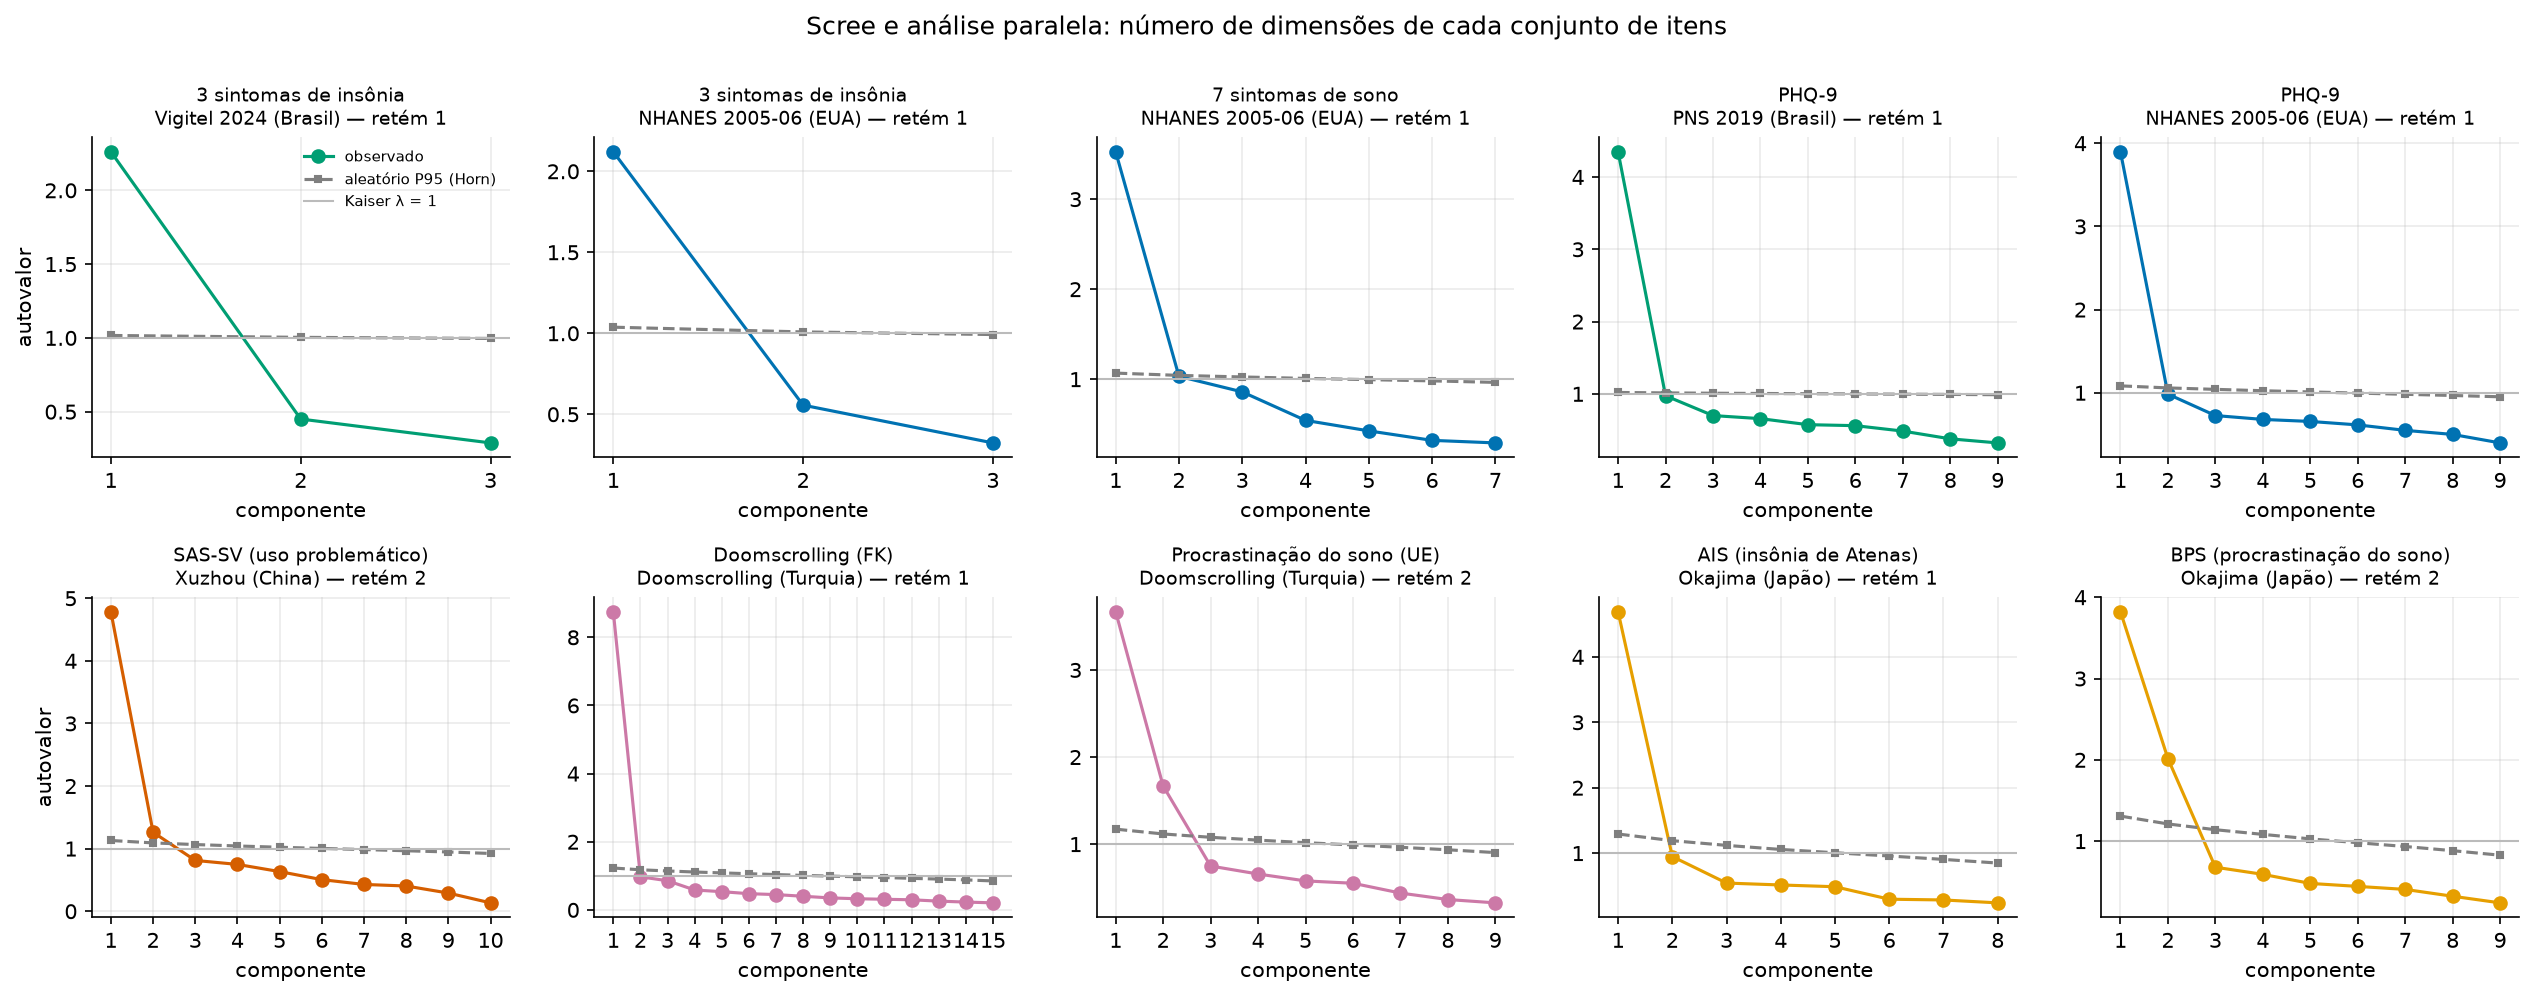

In [9]:
display(Image(filename=str(FIG / "scree_todos.png")))

**Leitura.** A análise paralela retém 1 dimensão nos dois conjuntos de insônia, nos dois PHQ-9, no doomscrolling
e na AIS; retém 2 no SAS-SV (Xuzhou), na procrastinação (Turquia) e no BPS (Japão). Nos 7 sintomas de sono do
NHANES, Kaiser apontaria 2 (λ2 = 1,032), mas o 2º autovalor não supera o P95 aleatório
(1,043): a regra do plano retém 1.

## Biplot: 7 sintomas de sono (NHANES)

O biplot mostra, no plano dos 2 primeiros componentes, as **cargas** (setas) e os **escores** (pontos). O CP1 é
"problema de sono em geral" (todas as setas para a direita); o CP2 separa os sintomas **noturnos** (adormecer,
acordar à noite, acordar cedo, remédio) dos **diurnos** (não descansado, sonolência, sono insuficiente).

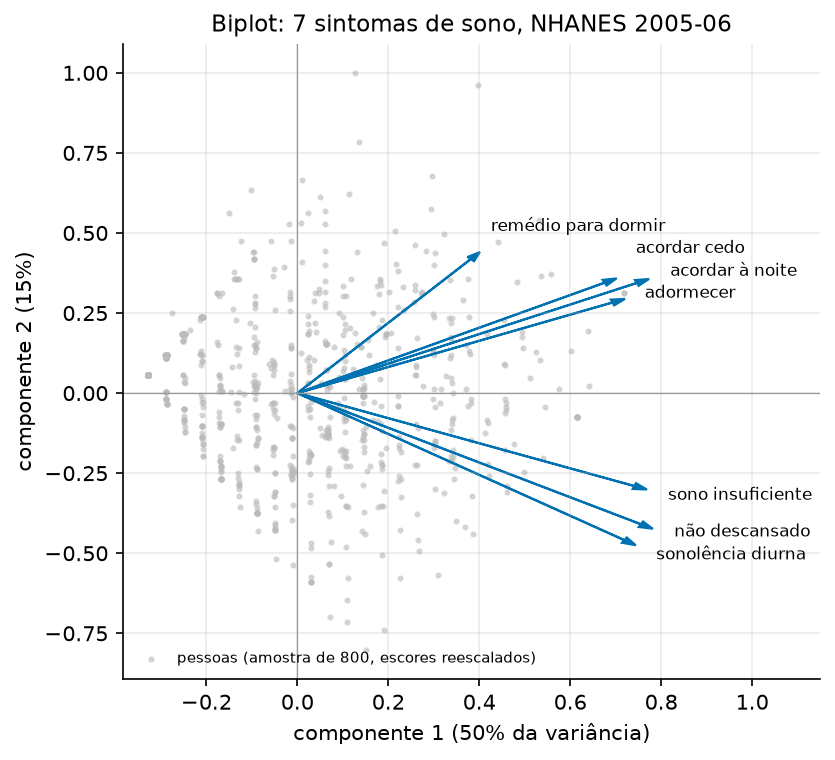

In [10]:
display(Image(filename=str(FIG / "biplot_sono7_nhanes.png")))

## Conclusão

- A PCA por SVD reproduz exatamente (até $10^{-8}$) a PCA de referência; os autovalores são $\sigma^2/(n-1)$.
- Os 3 sintomas de insônia formam um componente dominante no Brasil e nos EUA, com cargas quase idênticas.
- O número de dimensões dos outros instrumentos está em `resultados/002/tabelas/adequacao.csv`; a análise
  fatorial (notebook 03) confirma e interpreta essas dimensões.